In [3]:
from joblib import load
import sys
import pandas as pd
import numpy as np
import glob
# sys.path.append('/data/Phillippy/projects/pickettbd_data/parent-of-origin/pofo_tools/src/')
# sys.path.append('/data/Phillippy/projects/pickettbd_data/parent-of-origin/pofo_tools/src/')
# import pofo_tools
# from pofo_tools.utils import *
import seaborn as sns
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'  # Keep text as text (not paths)

figureDir = "/home/jhu/jkim789/projects_aphill27/projects/pooch/figures"
import os 
os.makedirs(figureDir, exist_ok=True)

In [9]:
xx = pd.read_csv("/path/to/project/pooch/findings/xist/chrX_balance.bed", sep='\t', header = None)
xx['sex'] = "XX"

xy = pd.read_csv("/path/to/project/pooch/findings/dhrsx_in_XY/chrX.DHRSX.methylation.bed", sep = '\t' , header = None)
xy['sex'] = "XY"

df = pd.concat([xx, xy])
df.columns = ['chr','start','end','tmp','total','meth','sample','hap', 'sex']
df.head()

,chr,start,end,tmp,total,meth,sample,hap,sex
0,chrX,1937651,1938190,chrX,720,208,HG00408,1,XX
1,chrX,58057992,58058138,chrX,151,115,HG00408,1,XX
2,chrX,1937651,1938190,chrX,622,282,HG00408,2,XX
3,chrX,58057992,58058138,chrX,176,139,HG00408,2,XX
4,chrX,1937651,1938190,chrX,804,235,HG00423,1,XX


In [10]:
# filter only DHRSX loucs iDMR
df = df.loc[(df['start']== 1937651) & (df['end'] == 1938190)]
del df['tmp']
df['hap'] = df['hap'].map({1:'Paternal',2:"Maternal","p":"Paternal","m":"Maternal"})
df['frac'] = df['meth'] / df['total']

In [14]:
# swap fractions for reversed parental haplotype assigned samples
df['frac_corrected'] = df['frac']

swap_samples  = ["HG03579", "HG02717", "HG02451"]

df.loc[df['sample'].isin(swap_samples)]

,chr,start,end,total,meth,sample,hap,sex,frac,frac_corrected
139,chrX,1937651,1938190,461,208,HG02451,Paternal,XX,0.451193,0.451193
141,chrX,1937651,1938190,681,189,HG02451,Maternal,XX,0.277533,0.277533
87,chrX,1937651,1938190,1299,1240,HG02717,Maternal,XY,0.954580,0.954580
88,chrX,1937651,1938190,1410,1305,HG02717,Paternal,XY,0.925532,0.925532
103,chrX,1937651,1938190,1035,551,HG03579,Maternal,XY,0.532367,0.532367
104,chrX,1937651,1938190,1173,504,HG03579,Paternal,XY,0.429668,0.429668


In [15]:
mat_mask = (df['sample'].isin(swap_samples)) & (df['hap'] == "Maternal")
pat_mask = (df['sample'].isin(swap_samples)) & (df['hap'] == "Paternal")
df.loc[mat_mask, "frac_corrected"] = df.loc[pat_mask, "frac"].values
df.loc[pat_mask, "frac_corrected"] = df.loc[mat_mask, "frac"].values

df.loc[df['sample'].isin(swap_samples)]

,chr,start,end,total,meth,sample,hap,sex,frac,frac_corrected
139,chrX,1937651,1938190,461,208,HG02451,Paternal,XX,0.451193,0.277533
141,chrX,1937651,1938190,681,189,HG02451,Maternal,XX,0.277533,0.451193
87,chrX,1937651,1938190,1299,1240,HG02717,Maternal,XY,0.954580,0.925532
88,chrX,1937651,1938190,1410,1305,HG02717,Paternal,XY,0.925532,0.954580
103,chrX,1937651,1938190,1035,551,HG03579,Maternal,XY,0.532367,0.429668
104,chrX,1937651,1938190,1173,504,HG03579,Paternal,XY,0.429668,0.532367


In [16]:
df_wide = df.pivot_table(index = ['sample', 'sex'], values = "frac_corrected", columns = "hap").reset_index()
df_wide['diff_methyl'] = df_wide['Maternal'] - df_wide['Paternal']
df_wide.head(2)

hap,sample,sex,Maternal,Paternal,diff_methyl
0,HG002,XY,0.935714,0.933333,0.002381
1,HG00408,XX,0.453376,0.288889,0.164487


In [17]:
len(set(df_wide['sample']))

123

In [18]:
df_wide.groupby("sex").size()

sex
XX    59
XY    64
dtype: int64

In [19]:
from scipy import stats


# Perform a two-sided paired t-test
result = stats.ttest_rel(df_wide.loc[df_wide['sex'] == "XX", "Maternal"], df_wide.loc[df_wide['sex'] == "XX", "Paternal"], nan_policy="omit")

print(f"t-statistic: {result.statistic:.4f}")
print(f"p-value: {result.pvalue:.4f}")
print(f"Degrees of freedom: {result.df}")

t-statistic: 8.3377
p-value: 0.0000
Degrees of freedom: 58


In [20]:
from scipy import stats

# Perform a two-sided paired t-test
result = stats.ttest_rel(df_wide.loc[df_wide['sex'] == "XY", "Maternal"], df_wide.loc[df_wide['sex'] == "XY", "Paternal"], nan_policy="omit")

print(f"t-statistic: {result.statistic:.4f}")
print(f"p-value: {result.pvalue:.4f}")
print(f"Degrees of freedom: {result.df}")


t-statistic: 2.5515
p-value: 0.0132
Degrees of freedom: 62


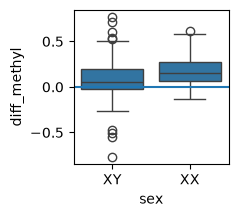

In [23]:
plt.figure(figsize = (2,2))
sns.boxplot(df_wide, x = "sex", y = "diff_methyl")
plt.axhline(0)

XX: n=59, t=8.338, p=1.668e-11
XY: n=63, t=2.552, p=1.321e-02


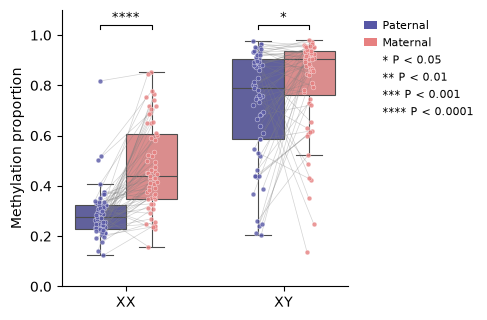

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from scipy import stats

palette = {
    "Maternal": "#e78080",
    "Paternal": "#5757A6"
}

sex_order = ["XX", "XY"]
hap_order = ["Paternal", "Maternal"]

# Pair maternal and paternal methylation by sample
df_wide = (
    df.pivot_table(
        index=["sample", "sex"],
        columns="hap",
        values="frac_corrected",
        aggfunc="mean"
    )
    .dropna(subset=["Maternal", "Paternal"])
    .reset_index()
)

df_plot = df_wide.melt(
    id_vars=["sample", "sex"],
    value_vars=hap_order,
    var_name="hap",
    value_name="frac_corrected"
)

fig, ax = plt.subplots(figsize=(5, 3.3))

# Boxplot
sns.boxplot(
    data=df_plot,
    x="sex",
    y="frac_corrected",
    hue="hap",
    order=sex_order,
    hue_order=hap_order,
    palette=palette,
    width=0.65,
    showfliers=False,
    linewidth=0.8,
    ax=ax
)

# Paired lines and dots
offset = {
    "Paternal": -0.1625,
    "Maternal": 0.1625
}

rng = np.random.default_rng(42)

for sex_idx, sex in enumerate(sex_order):

    sub = df_wide[df_wide["sex"] == sex]

    for _, row in sub.iterrows():

        jitter = rng.uniform(-0.035, 0.035)

        x_pat = sex_idx + offset["Paternal"] + jitter
        x_mat = sex_idx + offset["Maternal"] + jitter

        ax.plot(
            [x_pat, x_mat],
            [row["Paternal"], row["Maternal"]],
            color="gray",
            alpha=0.35,
            lw=0.5,
            zorder=3
        )

        ax.scatter(
            x_pat,
            row["Paternal"],
            color=palette["Paternal"],
            edgecolor="white",
            linewidth=0.3,
            s=12,
            alpha=0.8,
            zorder=4
        )

        ax.scatter(
            x_mat,
            row["Maternal"],
            color=palette["Maternal"],
            edgecolor="white",
            linewidth=0.3,
            s=12,
            alpha=0.8,
            zorder=4
        )

# ---------------------------------------
# Paired t-test + significance annotation
# ---------------------------------------

def p_to_stars(p):
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

for sex_idx, sex in enumerate(sex_order):

    sub = df_wide.loc[
        df_wide["sex"] == sex,
        ["Maternal", "Paternal"]
    ].replace([np.inf, -np.inf], np.nan).dropna()

    result = stats.ttest_rel(
        sub["Maternal"],
        sub["Paternal"]
    )

    p = result.pvalue
    stars = p_to_stars(p)

    print(f"{sex}: n={len(sub)}, t={result.statistic:.3f}, p={p:.3e}")

    # Bracket position
    x1 = sex_idx + offset["Paternal"]
    x2 = sex_idx + offset["Maternal"]

    y = 1.025
    h = 0.015

    ax.plot(
        [x1, x1, x2, x2],
        [y, y+h, y+h, y],
        color="black",
        lw=0.8,
        clip_on=False
    )

    ax.text(
        (x1 + x2) / 2,
        y + h + 0.005,
        stars,
        ha="center",
        va="bottom",
        fontsize=9
    )

# ---------------------------------------
# Formatting
# ---------------------------------------

ax.set_ylim(0, 1.10)
ax.set_xlabel("")
ax.set_ylabel("Methylation proportion")

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor=palette["Paternal"], label="Paternal"),
    Patch(facecolor=palette["Maternal"], label="Maternal"),
    Line2D([], [], color="none", label="* P < 0.05"),
    Line2D([], [], color="none", label="** P < 0.01"),
    Line2D([], [], color="none", label="*** P < 0.001"),
    Line2D([], [], color="none", label="**** P < 0.0001"),
]

ax.legend(
    handles=legend_elements,
    title="",
    frameon=False,
    fontsize=8,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    handlelength=1.2,
    handletextpad=0.5
)

sns.despine()
plt.tight_layout()

plt.savefig(
    f"{figureDir}/methylation_paired_boxplot.xx_vs_xy.dhrsx.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [25]:
df_wide = df.pivot_table(index = ['sample', 'sex'], values = "frac_corrected", columns = "hap").reset_index()
df_wide['diff_methyl'] = df_wide['Maternal'] - df_wide['Paternal']
df_wide.head(2)

hap,sample,sex,Maternal,Paternal,diff_methyl
0,HG002,XY,0.935714,0.933333,0.002381
1,HG00408,XX,0.453376,0.288889,0.164487


In [26]:
from scipy import stats

xx_diff = df_wide.loc[
    df_wide["sex"] == "XX", "diff_methyl"
].dropna()

xy_diff = df_wide.loc[
    df_wide["sex"] == "XY", "diff_methyl"
].dropna()

# Compare maternal-paternal differences between XX and XY
result = stats.ttest_ind(
    xx_diff,
    xy_diff,
    equal_var=False
)

print(f"t-statistic: {result.statistic:.4f}")
print(f"p-value: {result.pvalue:.3e}")

t-statistic: 2.3541
p-value: 2.044e-02


In [27]:
import numpy as np
from scipy import stats

mean_xx = xx_diff.mean()
mean_xy = xy_diff.mean()

difference = mean_xx - mean_xy

print(f"XX mean difference: {mean_xx:.4f}")
print(f"XY mean difference: {mean_xy:.4f}")
print(f"XX - XY difference: {difference:.4f}")
print(f"Difference in percentage points: {difference * 100:.2f}")

XX mean difference: 0.1846
XY mean difference: 0.0881
XX - XY difference: 0.0965
Difference in percentage points: 9.65
